# Imports

In [1]:
import subprocess
import sys
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

TEST = Path("test.py") if Path("test.py").exists() else Path("../test.py")
print(sys.executable)

C:\Users\Rene\Desktop\Pedagosko\FNM\modelska_fizika_vaje\venv\Scripts\python.exe


# Funkcije

In [2]:
def vsota_zanka(x):
    """Vsota kvadratov elementov z zanko for."""
    s = 0.0
    for v in x:
        s += v * v
    return s


def vsota_numpy(x):
    """Vsota kvadratov elementov z numpy (brez zanke)."""
    return np.sum(x * x)


def duseno_nihanje(t, A=1.0, beta=0.2, omega=2 * np.pi):
    """x(t) = A exp(-beta t) cos(omega t)."""
    return A * np.exp(-beta * t) * np.cos(omega * t)

# Testno območje

In [3]:
# P2: vsota kvadratov 1 + 4 + 9 = 14
print(vsota_zanka([1, 2, 3]), vsota_numpy(np.array([1, 2, 3])))

14.0 14


# Naloga 1

In [4]:
# Preizkus okolja z istim interpreterjem, kot ga uporablja jedro zvezka (Preglednica 1)
r = subprocess.run([sys.executable, str(TEST)], capture_output=True, text=True)
print(r.stdout, r.stderr)

Python 3.14.6 (C:\Users\Rene\Desktop\Pedagosko\FNM\modelska_fizika_vaje\venv\Scripts\python.exe)
  numpy           2.5.4
  scipy           1.18.1
  pandas          3.0.6
  matplotlib      3.11.2
  seaborn         0.13.2
  openpyxl        3.1.5
  opencv-python   5.0.0
  scikit-image    0.26.0
  astropy         8.0.2
  tqdm            4.70.1
  networkx        3.7
  sympy           1.14.0
  ipykernel       7.4.0
Vse BP
 


# Naloga 3

In [5]:
rng = np.random.default_rng(0)
for N in (10**4, 10**5, 10**6):
    x = rng.random(N)
    t0 = time.perf_counter()
    s1 = vsota_zanka(x)
    t1 = time.perf_counter()
    s2 = vsota_numpy(x)
    t2 = time.perf_counter()
    print(f"N = {N:7d}: zanka {1e3 * (t1 - t0):8.2f} ms, numpy {1e3 * (t2 - t1):6.3f} ms, "
          f"razmerje {(t1 - t0) / (t2 - t1):6.0f}, razlika vsot {abs(s1 - s2):.1e}")

N =   10000: zanka     1.72 ms, numpy  0.165 ms, razmerje     10, razlika vsot 5.0e-12
N =  100000: zanka    17.09 ms, numpy  0.390 ms, razmerje     44, razlika vsot 1.5e-10


N = 1000000: zanka   170.53 ms, numpy  4.342 ms, razmerje     39, razlika vsot 1.3e-08


# Naloga 4 - Slika 1

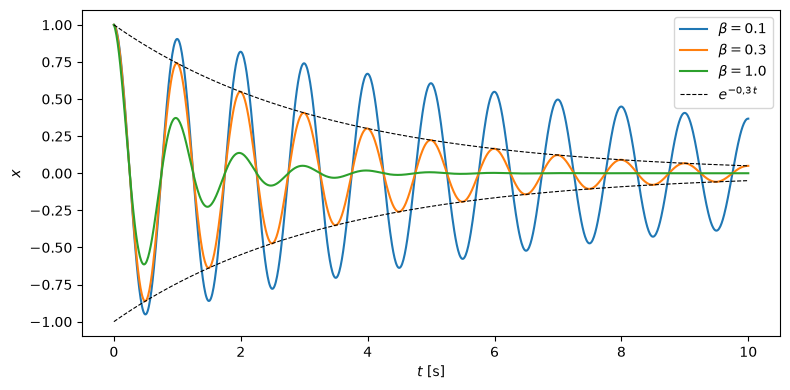

In [6]:
t = np.linspace(0, 10, 1000)
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
for beta in (0.1, 0.3, 1.0):
    ax.plot(t, duseno_nihanje(t, beta=beta), label=rf"$\beta = {beta}$")
ax.plot(t, np.exp(-0.3 * t), "k--", lw=0.8, label=r"$e^{-0{,}3\,t}$")
ax.plot(t, -np.exp(-0.3 * t), "k--", lw=0.8)
ax.set_xlabel("$t$ [s]")
ax.set_ylabel("$x$")
ax.legend()
fig.tight_layout()
plt.show()